In [1]:
#Importing libraries 
import numpy as np 
import pandas as pd 
import matplotlib.pyplot as plt
import seaborn as sns 
import warnings
warnings.filterwarnings('ignore')
import plotly.express as px

In [2]:
#Loading the dataset 
df = pd.read_csv(r"C:\Users\HP\Downloads\Data analytics python projects\Pizza sales analysis practice project\pizza_sales.csv")

#### METADATA OF DATA

In [3]:
#First five rows 
df.head()

,pizza_id,order_id,pizza_name_id,quantity,order_date,order_time,unit_price,total_price,pizza_size,pizza_category,pizza_ingredients,pizza_name
0,1,1,hawaiian_m,1,01-01-2015,11:38:36,13.25,13.25,M,Classic,"Sliced Ham, Pineapple, Mozzarella Cheese",The Hawaiian Pizza
1,2,2,classic_dlx_m,1,01-01-2015,11:57:40,16.00,16.00,M,Classic,"Pepperoni, Mushrooms, Red Onions, Red Peppers,...",The Classic Deluxe Pizza
2,3,2,five_cheese_l,1,01-01-2015,11:57:40,18.50,18.50,L,Veggie,"Mozzarella Cheese, Provolone Cheese, Smoked Go...",The Five Cheese Pizza
3,4,2,ital_supr_l,1,01-01-2015,11:57:40,20.75,20.75,L,Supreme,"Calabrese Salami, Capocollo, Tomatoes, Red Oni...",The Italian Supreme Pizza
4,5,2,mexicana_m,1,01-01-2015,11:57:40,16.00,16.00,M,Veggie,"Tomatoes, Red Peppers, Jalapeno Peppers, Red O...",The Mexicana Pizza


In [4]:
# Dimension of the data
print(df.shape)

(48620, 12)


In [5]:
#Rows and columns 
print('Number of rows: ',df.shape[0])
print('Number of columns: ',df.shape[1])

Number of rows:  48620
Number of columns:  12


In [6]:
#Information of the data 
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 48620 entries, 0 to 48619
Data columns (total 12 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   pizza_id           48620 non-null  int64  
 1   order_id           48620 non-null  int64  
 2   pizza_name_id      48620 non-null  object 
 3   quantity           48620 non-null  int64  
 4   order_date         48620 non-null  object 
 5   order_time         48620 non-null  object 
 6   unit_price         48620 non-null  float64
 7   total_price        48620 non-null  float64
 8   pizza_size         48620 non-null  object 
 9   pizza_category     48620 non-null  object 
 10  pizza_ingredients  48620 non-null  object 
 11  pizza_name         48620 non-null  object 
dtypes: float64(2), int64(3), object(7)
memory usage: 4.5+ MB


In [7]:
# Converting order date to datetime column 
df['order_date']=pd.to_datetime(df['order_date'],format="%d-%m-%Y")

In [8]:
#Converting order time column to time type 
df['order_time'] = pd.to_datetime(df['order_time'],format="%H:%M:%S").dt.time 

In [12]:
#Checking the data 
df.head()

,pizza_id,order_id,pizza_name_id,quantity,order_date,order_time,unit_price,total_price,pizza_size,pizza_category,pizza_ingredients,pizza_name
0,1,1,hawaiian_m,1,2015-01-01,11:38:36,13.25,13.25,M,Classic,"Sliced Ham, Pineapple, Mozzarella Cheese",The Hawaiian Pizza
1,2,2,classic_dlx_m,1,2015-01-01,11:57:40,16.00,16.00,M,Classic,"Pepperoni, Mushrooms, Red Onions, Red Peppers,...",The Classic Deluxe Pizza
2,3,2,five_cheese_l,1,2015-01-01,11:57:40,18.50,18.50,L,Veggie,"Mozzarella Cheese, Provolone Cheese, Smoked Go...",The Five Cheese Pizza
3,4,2,ital_supr_l,1,2015-01-01,11:57:40,20.75,20.75,L,Supreme,"Calabrese Salami, Capocollo, Tomatoes, Red Oni...",The Italian Supreme Pizza
4,5,2,mexicana_m,1,2015-01-01,11:57:40,16.00,16.00,M,Veggie,"Tomatoes, Red Peppers, Jalapeno Peppers, Red O...",The Mexicana Pizza


In [15]:
#Checking data types 
df.dtypes

pizza_id                      int64
order_id                      int64
pizza_name_id                object
quantity                      int64
order_date           datetime64[ns]
order_time                   object
unit_price                  float64
total_price                 float64
pizza_size                   object
pizza_category               object
pizza_ingredients            object
pizza_name                   object
dtype: object

In [9]:
# Replacing pizza size feature value abbrevations with long forms for better analysis 
df['pizza_size'].value_counts()

pizza_size
L      18526
M      15385
S      14137
XL       544
XXL       28
Name: count, dtype: int64

In [10]:
df['pizza_size']=df['pizza_size'].replace({
    'L':'Large',
    'M':'Medium',
    'S':'Small',
    'XL':'X_Large',
    'XXL':'Double_X_Large'})

In [11]:
#Checking the column 
df['pizza_size'].value_counts()

pizza_size
Large             18526
Medium            15385
Small             14137
X_Large             544
Double_X_Large       28
Name: count, dtype: int64

In [12]:
#Statistical information of the numeric features 
df[['quantity','unit_price','total_price']].describe()

,quantity,unit_price,total_price
count,48620.000000,48620.000000,48620.000000
mean,1.019622,16.494132,16.821474
std,0.143077,3.621789,4.437398
min,1.000000,9.750000,9.750000
25%,1.000000,12.750000,12.750000
50%,1.000000,16.500000,16.500000
75%,1.000000,20.250000,20.500000
max,4.000000,35.950000,83.000000


### KPI's 

In [14]:
total_revenue = df['total_price'].sum() 
total_pizzas_sold = df['quantity'].sum() 
total_orders = df['order_id'].nunique() 
avg_order_value = total_revenue/total_orders 
avg_pizza_per_order = total_pizzas_sold/total_orders 


# Displaying the results 
print(f'Total Revenue: {total_revenue:.2f}$ ')
print(f'Total Pizzas Sold: {total_pizzas_sold}')
print(f'Total Orders: {total_orders}')
print(f'Average Order Value: {avg_order_value:.2f}$')
print(f'Average Pizza Per Order: {avg_pizza_per_order:.2f}')

Total Revenue: 817860.05$ 
Total Pizzas Sold: 49574
Total Orders: 21350
Average Order Value: 38.31$
Average Pizza Per Order: 2.32


### Ingredients Analysis

In [24]:
ingredients = df['pizza_ingredients'].str.split(',').explode().str.strip().value_counts().reset_index().rename(columns={'index':'pizza_ingredients','count':'counts'})


In [25]:
ingredients

,pizza_ingredients,counts
0,Garlic,27422
1,Tomatoes,26601
2,Red Onions,19547
3,Red Peppers,16284
4,Mozzarella Cheese,10333
...,...,...
60,Brie Carre Cheese,480
61,Prosciutto,480
62,Caramelized Onions,480
63,Pears,480


In [30]:
Top_10_ingredients = ingredients.head(10)



In [31]:
Top_10_ingredients

,pizza_ingredients,counts
0,Garlic,27422
1,Tomatoes,26601
2,Red Onions,19547
3,Red Peppers,16284
4,Mozzarella Cheese,10333
5,Pepperoni,10300
6,Spinach,10012
7,Mushrooms,9624
8,Chicken,8443
9,Capocollo,6572


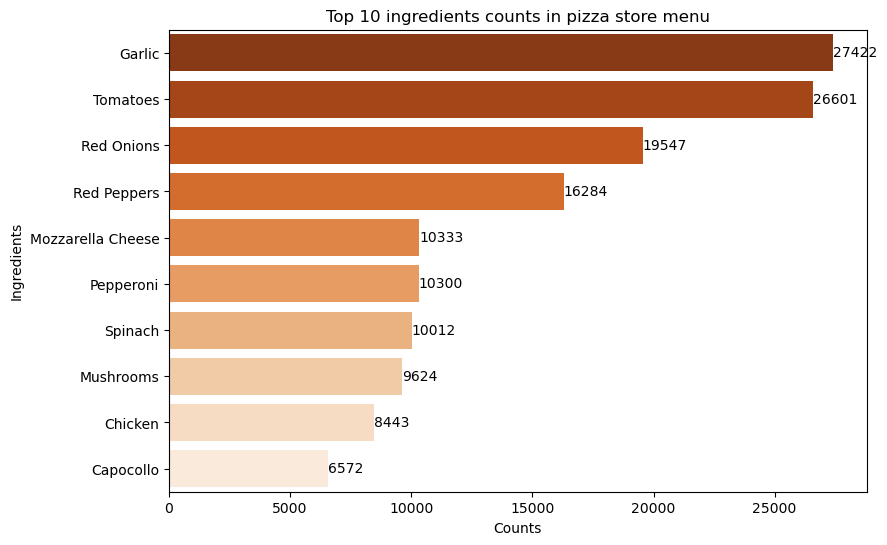

In [36]:
plt.figure(figsize=(9,6))
ax=sns.barplot(Top_10_ingredients,
            y='pizza_ingredients',
            x='counts',
            palette='Oranges_r',
            errorbar=None)
for i in ax.containers:
    ax.bar_label(i,fmt='%.0f',padding=0)

plt.title('Top 10 ingredients counts in pizza store menu')
plt.xlabel('Counts')
plt.ylabel('Ingredients')
plt.show()

### Daily Trend on basis of Total orders and Total revenue 

In [38]:
df['order_days'] = df['order_date'].dt.day_name() 

weekday_order = ['Monday','Tuesday','Wednesday','Thursday','Friday','Saturday','Sunday'] 

df['order_days']= pd.Categorical(df['order_days'],categories=weekday_order,ordered=True)

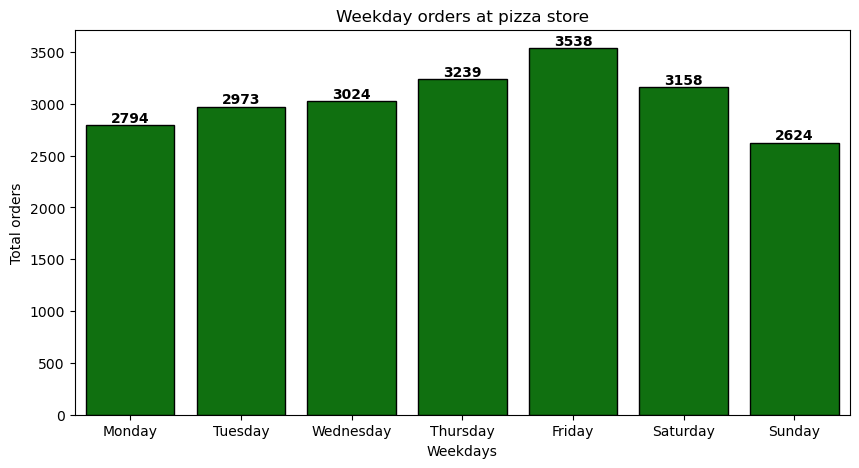

In [44]:
#Grouping order days with total orders 
day_wise_orders = df.groupby('order_days')['order_id'].nunique().reset_index() 

# Plotting bar plot to visualize the results 
plt.figure(figsize=(10,5))
ax=sns.barplot(day_wise_orders,
            x='order_days',
            y='order_id',
            color='green',
            edgecolor='black')
for i in ax.containers:
    ax.bar_label(i,fontweight='bold',label_type='edge')

plt.title('Weekday orders at pizza store')
plt.xlabel('Weekdays')
plt.ylabel('Total orders')
plt.show()

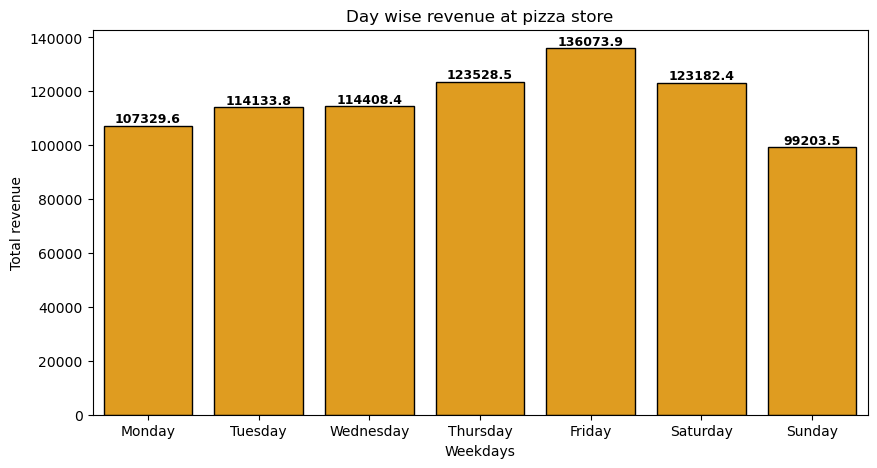

In [46]:
# Grouping weekdays with total revenue 
day_wise_revenue = df.groupby('order_days')['total_price'].sum().reset_index()

#Plotting the bar plot to visualize the result 
plt.figure(figsize=(10,5))
ax=sns.barplot(day_wise_revenue,
            x='order_days',
            y='total_price',
            color='orange',
            edgecolor='black',
            errorbar=None)
for i in ax.containers:
    ax.bar_label(i,fontweight='bold',fmt='%.1f',fontsize=9,label_type='edge')

plt.title('Day wise revenue at pizza store')
plt.xlabel('Weekdays')
plt.ylabel('Total revenue')
plt.show()

### Hourly Trends on basis of Total orders and Total revenue

In [49]:
df['order_time'] = pd.to_datetime(df['order_time'],format='%H:%M:%S')

In [51]:
# Order hour feature for further analysis 
df['order_hour'] = df['order_time'].dt.hour

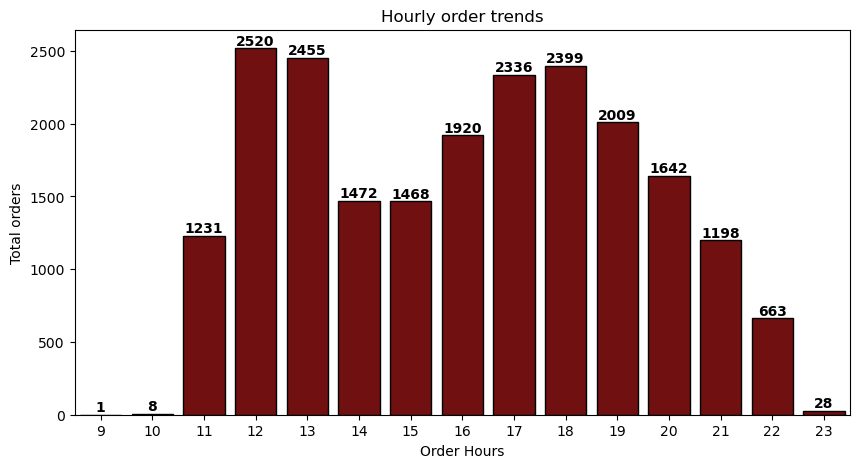

In [56]:
hourly_orders = df.groupby('order_hour')['order_id'].nunique().reset_index() 

# Plotting barplot to visualize the results 
plt.figure(figsize=(10,5))
ax=sns.barplot(hourly_orders,
            x='order_hour',
            y='order_id',
            color='maroon',
            edgecolor='black',
            errorbar=None)
for i in ax.containers:
    ax.bar_label(i,fontweight='bold',fmt='%.0f',fontsize=10,label_type='edge')

plt.title('Hourly order trends')
plt.xlabel('Order Hours')
plt.ylabel('Total orders')
plt.show()

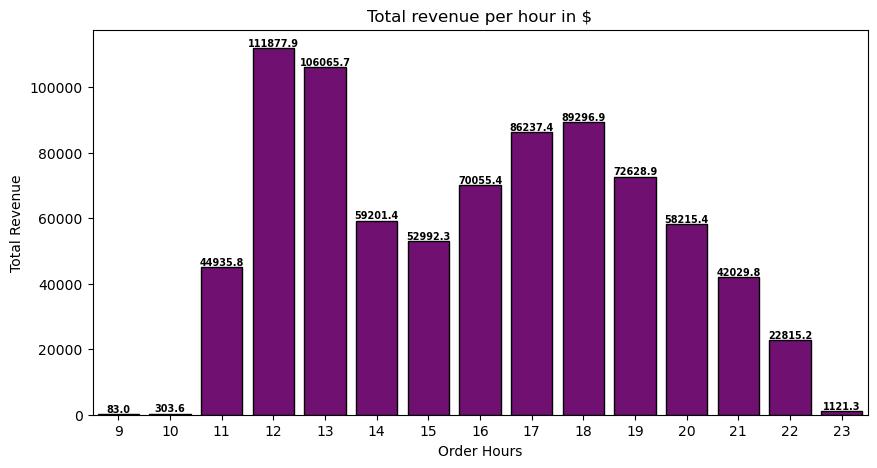

In [59]:
revenue_per_hour = df.groupby('order_hour')['total_price'].sum().reset_index()

#Plotting the results 
plt.figure(figsize=(10,5))
ax=sns.barplot(revenue_per_hour,
            x='order_hour',
            y='total_price',
            color='purple',
            edgecolor='black',
            errorbar=None)
for i in ax.containers:
    ax.bar_label(i,fontweight='bold',fmt='%.1f',fontsize=7,label_type='edge')

plt.title('Total revenue per hour in $')
plt.xlabel('Order Hours')
plt.ylabel('Total Revenue')
plt.show()

### Monthly Trends on the basis of Total orders and Total revenue

In [60]:
df['order_month'] = df['order_date'].dt.month_name() 

In [62]:
monthly_order = ['January','February','March','April','May','June','July','August','September','October','November','December'] 

df['order_month']= pd.Categorical(df['order_month'],categories=monthly_order,ordered=True)

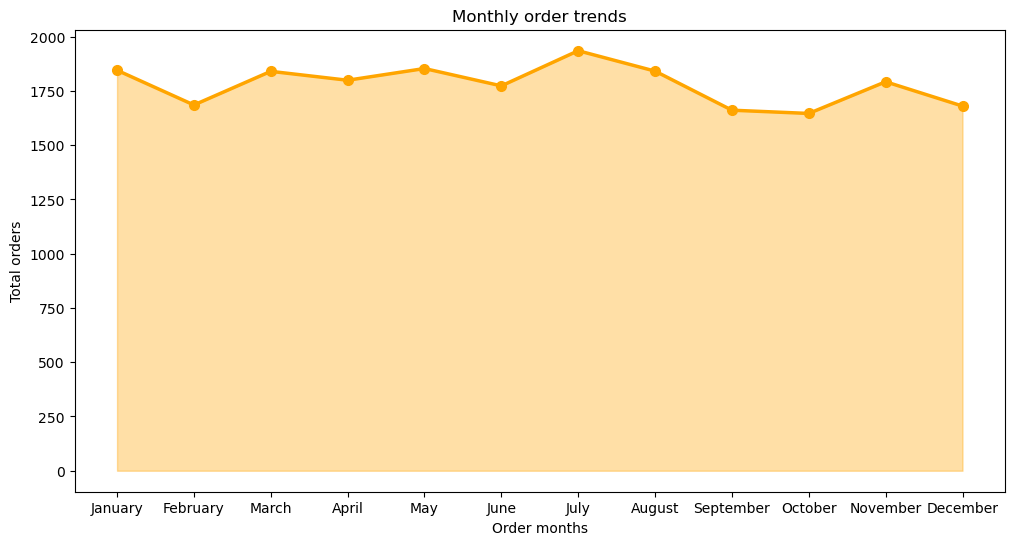

In [65]:
monthly_orders = df.groupby('order_month')['order_id'].nunique().reset_index()

#Plotting line plot to indicate monthly order trends 
plt.figure(figsize=(12,6))
plt.plot(
    monthly_orders['order_month'],
    monthly_orders['order_id'],
    color='orange',
    marker='o',
    markersize=7,
    linewidth=2.5,
    label='Monthly Orders')


plt.fill_between(
    monthly_orders['order_month'],
    monthly_orders['order_id'],
    color='orange',
    alpha=0.35)

plt.title('Monthly order trends')
plt.xlabel('Order months')
plt.ylabel('Total orders') 
plt.show()

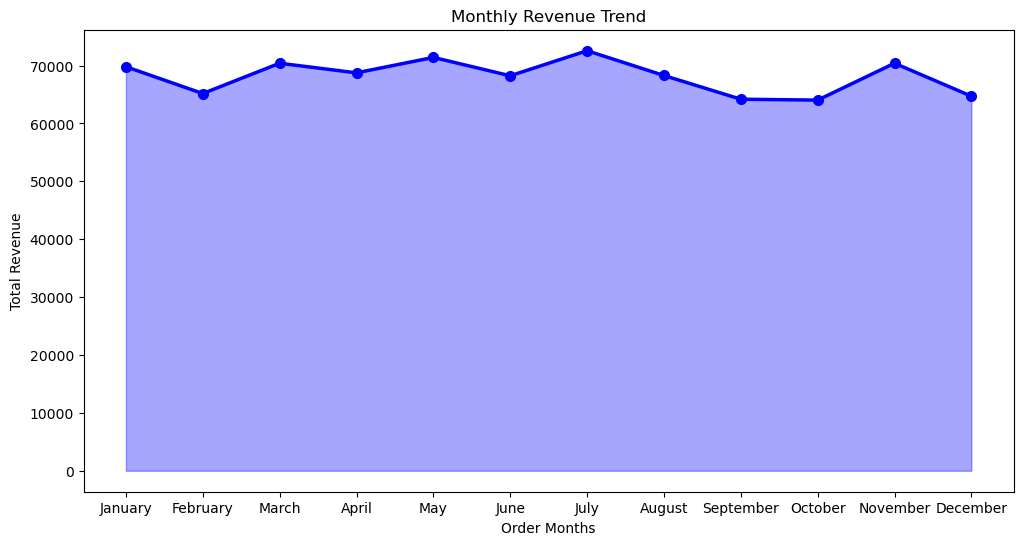

In [68]:
month_wise_revenue = df.groupby('order_month')['total_price'].sum().reset_index()

#Plotting a line chart 
plt.figure(figsize=(12,6))

plt.plot(
    month_wise_revenue['order_month'],
    month_wise_revenue['total_price'],
    marker='o',
    markersize=7,
    color='blue',
    linewidth=2.5,
    label='Monthly Revenue')

plt.fill_between(
    month_wise_revenue['order_month'],
    month_wise_revenue['total_price'],
    color='blue',
    alpha=0.35)

plt.title('Monthly Revenue Trend')
plt.xlabel('Order Months')
plt.ylabel('Total Revenue')
plt.show()
    
    

### % Sales by Category 

In [72]:
pizza_category_sales = df.groupby('pizza_category')['total_price'].sum().reset_index()

pizza_category_sales['Total_revenue'] = pizza_category_sales['total_price'].sum()

In [79]:
pizza_category_sales['%_sales'] = (pizza_category_sales['total_price']/pizza_category_sales['Total_revenue'])*100

In [81]:
pizza_category_sales['%_sales'] = pizza_category_sales['%_sales'].round(2)

In [83]:
pizza_category_sales.sort_values(by='%_sales',ascending=False,inplace=True)

In [84]:
pizza_category_sales

,pizza_category,total_price,Total_revenue,%_sales
1,Classic,220053.10,817860.05,26.91
2,Supreme,208197.00,817860.05,25.46
0,Chicken,195919.50,817860.05,23.96
3,Veggie,193690.45,817860.05,23.68


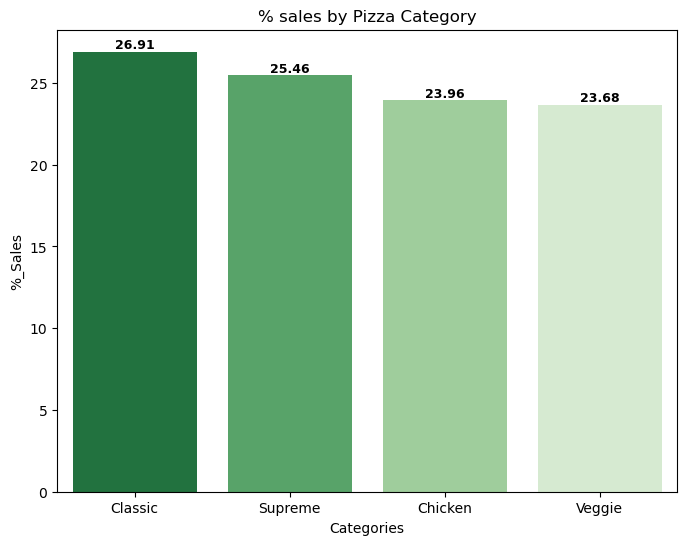

In [85]:
#Plotting bar plot to visualize the result 
plt.figure(figsize=(8,6))
ax=sns.barplot(pizza_category_sales,
            x='pizza_category',
            y='%_sales',
            palette='Greens_r',
            errorbar=None)
for i in ax.containers:
    ax.bar_label(i,fontweight='bold',fmt='%.2f',fontsize=9,label_type='edge')

plt.title('% sales by Pizza Category')
plt.xlabel('Categories')
plt.ylabel('%_Sales')
plt.show()
            

### % sales by pizza size and category

In [87]:
sales_pivot=df.pivot_table(
    index='pizza_category',
    columns='pizza_size',
    values='total_price',
    aggfunc='sum',
    fill_value=0 )

In [91]:
sales_pct= sales_pivot/sales_pivot.sum().sum()*100

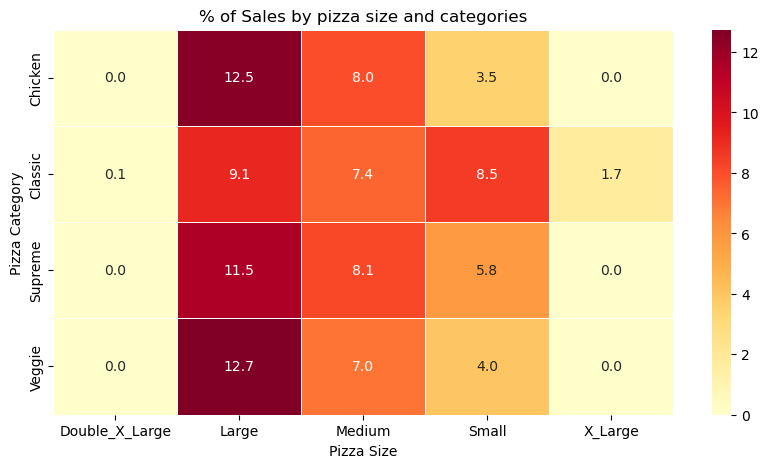

In [93]:
#Plotting a heatmap to display the results 
plt.figure(figsize=(10,5))
sns.heatmap(sales_pct,annot=True,fmt='.1f',cmap='YlOrRd',linewidths=0.5)
plt.title('% of Sales by pizza size and categories')
plt.xlabel('Pizza Size')
plt.ylabel('Pizza Category')
plt.show()

### Total Pizzas sold by pizza categories

In [98]:
category_wise_pizza_sold = df.groupby('pizza_category')['quantity'].sum().reset_index()

category_wise_pizza_sold['Total_quantity'] = category_wise_pizza_sold['quantity'].sum() 

category_wise_pizza_sold['%_quantities'] = (category_wise_pizza_sold['quantity']/category_wise_pizza_sold['Total_quantity'])*100 

category_wise_pizza_sold['%_quantitites'] = category_wise_pizza_sold['%_quantities'].round(2)

category_wise_pizza_sold

,pizza_category,quantity,Total_quantity,%_quantities,%_quantitites
0,Chicken,11050,49574,22.289910,22.29
1,Classic,14888,49574,30.031872,30.03
2,Supreme,11987,49574,24.180014,24.18
3,Veggie,11649,49574,23.498205,23.50


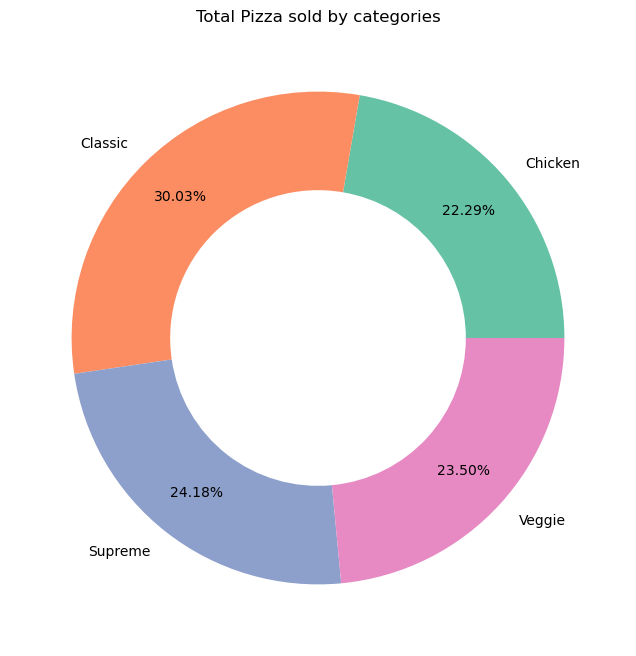

In [105]:
#Plotting a donut chart to display the output 
plt.figure(figsize=(10,8))
plt.pie(
    category_wise_pizza_sold['quantity'],
    labels=category_wise_pizza_sold['pizza_category'],
    autopct='%1.2f%%',
    pctdistance=0.80,
    colors=sns.color_palette('Set2'),
    wedgeprops = {'width':0.4}
)

plt.title('Total Pizza sold by categories')
plt.show()
    


### Top 5 best selling pizzas by revenue and orders 

In [3]:
Top_5_ordered_pizza = df.groupby('pizza_name')['order_id'].nunique().sort_values(ascending=False).head().reset_index()

Top_5_ordered_pizza

,pizza_name,order_id
0,The Classic Deluxe Pizza,2329
1,The Hawaiian Pizza,2280
2,The Pepperoni Pizza,2278
3,The Barbecue Chicken Pizza,2273
4,The Thai Chicken Pizza,2225


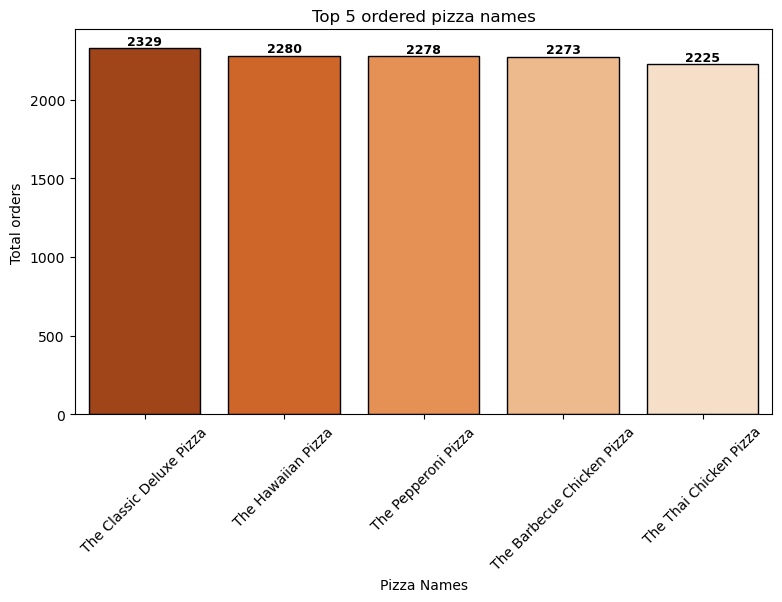

In [4]:
#Plotting horizontal bar chart 
plt.figure(figsize=(9,5))
ax=sns.barplot(Top_5_ordered_pizza,
            x='pizza_name',
            y='order_id',
            errorbar=None,
            palette='Oranges_r',
            edgecolor='black')
for i in ax.containers:
    ax.bar_label(i,fontweight='bold',fmt='%.0f',fontsize=9,label_type='edge')

plt.title('Top 5 ordered pizza names')
plt.xlabel('Pizza Names')
plt.ylabel('Total orders')
plt.xticks(rotation=45)
plt.show()

In [119]:
Top_5_pizza_revenues = df.groupby('pizza_name')['total_price'].sum().sort_values(ascending=False).head().reset_index()

Top_5_pizza_revenues

,pizza_name,total_price
0,The Thai Chicken Pizza,43434.25
1,The Barbecue Chicken Pizza,42768.00
2,The California Chicken Pizza,41409.50
3,The Classic Deluxe Pizza,38180.50
4,The Spicy Italian Pizza,34831.25


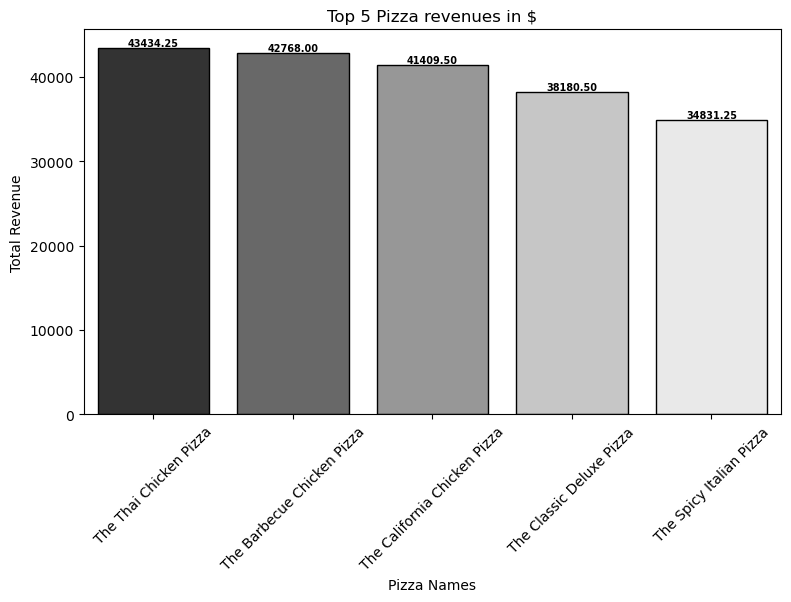

In [121]:
#Plotting the results 
plt.figure(figsize=(9,5))
ax=sns.barplot(Top_5_pizza_revenues,
            x='pizza_name',
            y='total_price',
            errorbar=None,
            edgecolor='black',
            palette='Greys_r')

for i in ax.containers:
    ax.bar_label(i,fontweight='bold',fmt='%.2f',fontsize=7,label_type='edge')

plt.title('Top 5 Pizza revenues in $')
plt.xlabel('Pizza Names')
plt.ylabel('Total Revenue')
plt.xticks(rotation=45)
plt.show()

In [124]:
least_5_ordered_pizza = df.groupby('pizza_name')['order_id'].nunique().sort_values(ascending=True).head().reset_index()

least_5_ordered_pizza

,pizza_name,order_id
0,The Brie Carre Pizza,480
1,The Mediterranean Pizza,912
2,The Spinach Supreme Pizza,918
3,The Calabrese Pizza,918
4,The Chicken Pesto Pizza,938


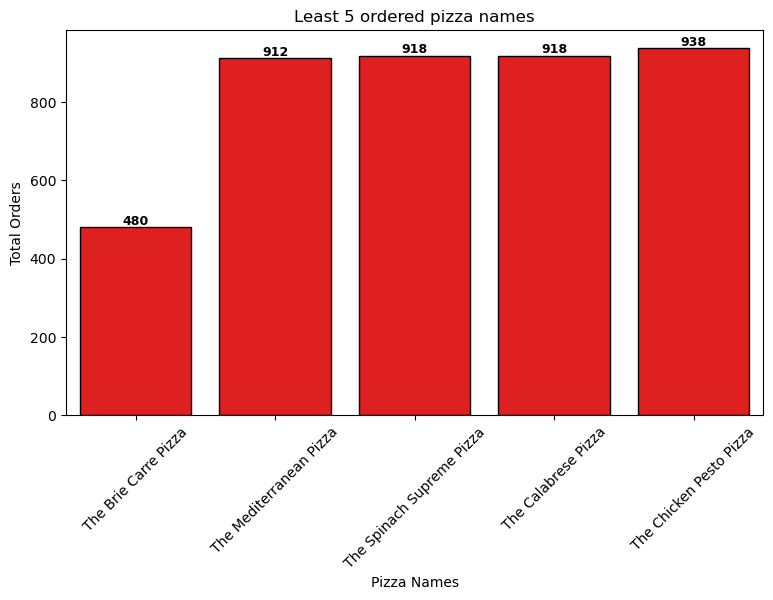

In [127]:
plt.figure(figsize=(9,5))
ax=sns.barplot(least_5_ordered_pizza,
            x='pizza_name',
            y='order_id',
            errorbar=None,
            edgecolor='black',
            color='red')

for i in ax.containers:
    ax.bar_label(i,fontweight='bold',fmt='%.0f',fontsize=9,label_type='edge')

plt.title('Least 5 ordered pizza names')
plt.xlabel('Pizza Names')
plt.ylabel('Total Orders')
plt.xticks(rotation=45)
plt.show()

In [128]:
least_5_pizza_revenue = df.groupby('pizza_name')['total_price'].sum().sort_values(ascending=True).head().reset_index()

least_5_pizza_revenue

,pizza_name,total_price
0,The Brie Carre Pizza,11588.50
1,The Green Garden Pizza,13955.75
2,The Spinach Supreme Pizza,15277.75
3,The Mediterranean Pizza,15360.50
4,The Spinach Pesto Pizza,15596.00


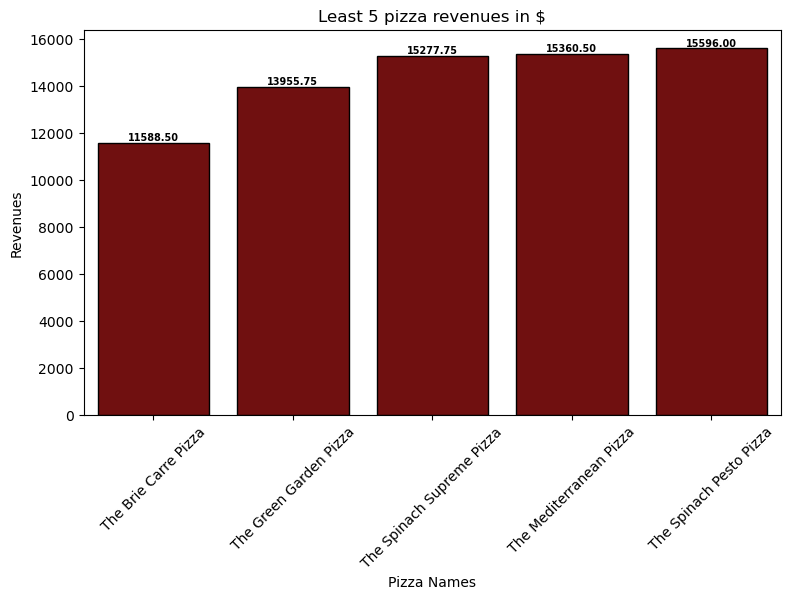

In [130]:
plt.figure(figsize=(9,5))
ax=sns.barplot(least_5_pizza_revenue,
            x='pizza_name',
            y='total_price',
            errorbar=None,
            edgecolor='black',
            color='maroon')

for i in ax.containers:
    ax.bar_label(i,fontweight='bold',fmt='%.2f',fontsize=7,label_type='edge')

plt.title('Least 5 pizza revenues in $')
plt.xlabel('Pizza Names')
plt.ylabel('Revenues')
plt.xticks(rotation=45)
plt.show()